In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/used_cars.csv")
print(df.shape)
df.head(10)

(4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"
5,Acura,ILX 2.4L,2016,"136,397 mi.",Gasoline,2.4 Liter,F,Silver,Ebony.,None reported,NaN,"$14,798"
6,Audi,S3 2.0T Premium Plus,2017,"84,000 mi.",Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,"$31,000"
7,BMW,740 iL,2001,"242,000 mi.",Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,"$7,300"
8,Lexus,RC 350 F Sport,2021,"23,436 mi.",Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,None reported,Yes,"$41,927"
9,Tesla,Model X Long Range Plus,2020,"34,000 mi.",NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,"$69,950"


In [3]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Unique values per column:")
print(df.nunique())
print()
print("Duplicated rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB

Missing values per column:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
pric

In [4]:
for col in ["fuel_type", "accident", "clean_title"]:
    print(df[col].value_counts(dropna=False))
    print()

print(df["brand"].value_counts())

fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Tesla             87
Kia               76
Hyundai           72
Mazda             64
Acura             64
Subaru            64
Honda             63
Volkswagen        59
INFINITI          59
Lincoln           52
Jaguar  

In [5]:
print(df["transmission"].value_counts().head(30))
print()
print(df["engine"].sample(30, random_state=42).to_string())

transmission
A/T                                  1037
8-Speed A/T                           406
Transmission w/Dual Shift Mode        398
6-Speed A/T                           362
6-Speed M/T                           248
Automatic                             237
7-Speed A/T                           209
8-Speed Automatic                     176
10-Speed A/T                          119
5-Speed A/T                            86
9-Speed A/T                            74
6-Speed Automatic                      73
4-Speed A/T                            72
1-Speed A/T                            64
CVT Transmission                       62
5-Speed M/T                            59
10-Speed Automatic                     56
9-Speed Automatic                      47
M/T                                    40
Automatic CVT                          37
7-Speed Automatic with Auto-Shift      24
1-Speed Automatic                      14
7-Speed M/T                            10
8-Speed Automatic wit

In [6]:
temp = df.copy()

temp["price"] = temp["price"].str.replace("$", "", regex=False).str.replace(",", "", regex=False)
temp["price"] = pd.to_numeric(temp["price"], errors="coerce")

temp["milage"] = temp["milage"].str.replace(" mi.", "", regex=False).str.replace(",", "", regex=False)
temp["milage"] = pd.to_numeric(temp["milage"], errors="coerce")

print("price NaN after conversion:", temp["price"].isnull().sum())
print("milage NaN after conversion:", temp["milage"].isnull().sum())
print()
print(temp[["price", "milage", "model_year"]].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.998]))
print()

cols = ["brand", "model", "model_year", "milage", "price"]
print("10 cheapest cars:")
print(temp.sort_values("price").head(10)[cols])
print()
print("10 most expensive cars:")
print(temp.sort_values("price").tail(10)[cols])

price NaN after conversion: 0
milage NaN after conversion: 0

              price         milage   model_year
count  4.009000e+03    4009.000000  4009.000000
mean   4.455319e+04   64717.551010  2015.515590
std    7.871064e+04   52296.599459     6.104816
min    2.000000e+03     100.000000  1974.000000
1%     4.000000e+03     634.680000  1997.080000
5%     6.996600e+03    3541.200000  2004.000000
25%    1.720000e+04   23044.000000  2012.000000
50%    3.100000e+04   52775.000000  2017.000000
75%    4.999000e+04   94100.000000  2020.000000
95%    1.116000e+05  165000.000000  2023.000000
99%    2.727133e+05  222428.000000  2023.000000
99.8%  4.918065e+05  269838.840000  2023.000000
max    2.954083e+06  405000.000000  2024.000000

10 cheapest cars:
        brand                model  model_year  milage  price
425   Lincoln       Aviator Luxury        2005  140000   2000
89     Subaru       Forester 2.5 X        2004  210703   2300
3640   Nissan           Maxima GLE        2000  194277   2300

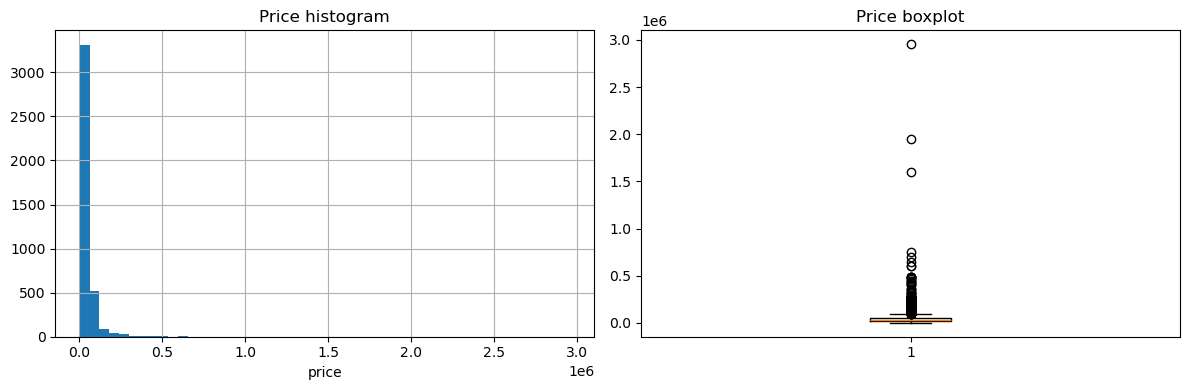

Price skewness: 19.51355120421606


In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
temp["price"].hist(bins=50)
plt.title("Price histogram")
plt.xlabel("price")

plt.subplot(1, 2, 2)
plt.boxplot(temp["price"].dropna())
plt.title("Price boxplot")

plt.tight_layout()
plt.show()

print("Price skewness:", temp["price"].skew())

In [8]:
%load_ext autoreload
%autoreload 2

from cleaning import clean_data

raw = pd.read_csv("data/used_cars.csv")
clean = clean_data(raw)

print("raw:", raw.shape, " clean:", clean.shape)
print()
print("Removed rows:")
print(raw.loc[raw.index.difference(clean.index), ["brand", "model", "model_year", "price"]])
print()
print("Missing ratio per column:")
print(clean.isnull().mean().round(3))
print()
print(clean.describe().round(2))
print()
for col in ["fuel_type", "transmission_type", "accident", "clean_title"]:
    print(clean[col].value_counts())
    print()
print("Engine strings where HP was not found:")
print(raw.loc[clean.index[clean["horsepower"].isna()], "engine"].value_counts().head(15))
print()
print("Engine strings of rows with Unknown fuel type:")
print(raw.loc[clean.index[clean["fuel_type"] == "Unknown"], "engine"].value_counts().head(15))
print()
print("Raw transmission text that became Other:")
print(raw.loc[clean.index[clean["transmission_type"] == "Other"], "transmission"].value_counts())

raw: (4009, 12)  clean: (4001, 11)

Removed rows:
            brand                    model  model_year       price
229       Bugatti  Veyron 16.4 Grand Sport        2011  $1,950,995
624   Rolls-Royce                 Cullinan        2022    $695,000
693      Maserati        Quattroporte Base        2005  $2,954,083
979   Lamborghini       Aventador SVJ Base        2019    $649,999
1356  Lamborghini       Aventador SVJ Base        2021    $749,950
1508  Rolls-Royce                  Phantom        2018    $599,000
1615  Rolls-Royce                  Phantom        2023    $599,995
3046      Porsche          Carrera GT Base        2005  $1,599,000

Missing ratio per column:
brand                0.000
fuel_type            0.000
transmission_type    0.000
accident             0.000
clean_title          0.000
milage               0.000
car_age              0.000
horsepower           0.201
engine_liters        0.012
cylinders            0.061
price                0.000
dtype: float64

       

In [9]:
print("Engine strings of rows marked Electric:")
print(raw.loc[clean.index[clean["fuel_type"] == "Electric"], "engine"].value_counts())

Engine strings of rows marked Electric:
engine
Electric                                             17
835.0HP Electric Motor Electric Fuel System          16
425.0HP Electric Motor Electric Fuel System          16
455.0HP Electric Motor Electric Fuel System          12
518.0HP Electric Motor Electric Fuel System          11
Electric Motor Electric Fuel System                   9
271.0HP Electric Motor Electric Fuel System           9
670.0HP Electric Motor Electric Fuel System           7
170.0HP 0.65L Electric Motor Electric Fuel System     5
200.0HP Electric Motor Electric Fuel System           4
355.0HP Electric Motor Electric Fuel System           3
329.0HP Electric Motor Electric Fuel System           3
480.0HP Electric Motor Electric Fuel System           3
295.0HP Electric Motor Electric Fuel System           3
320.0HP Electric Motor Electric Fuel System           3
Dual Motor - Standard                                 3
201.0HP Electric Motor Electric Fuel System           3
5

In [10]:
import os
os.makedirs("figures", exist_ok=True)

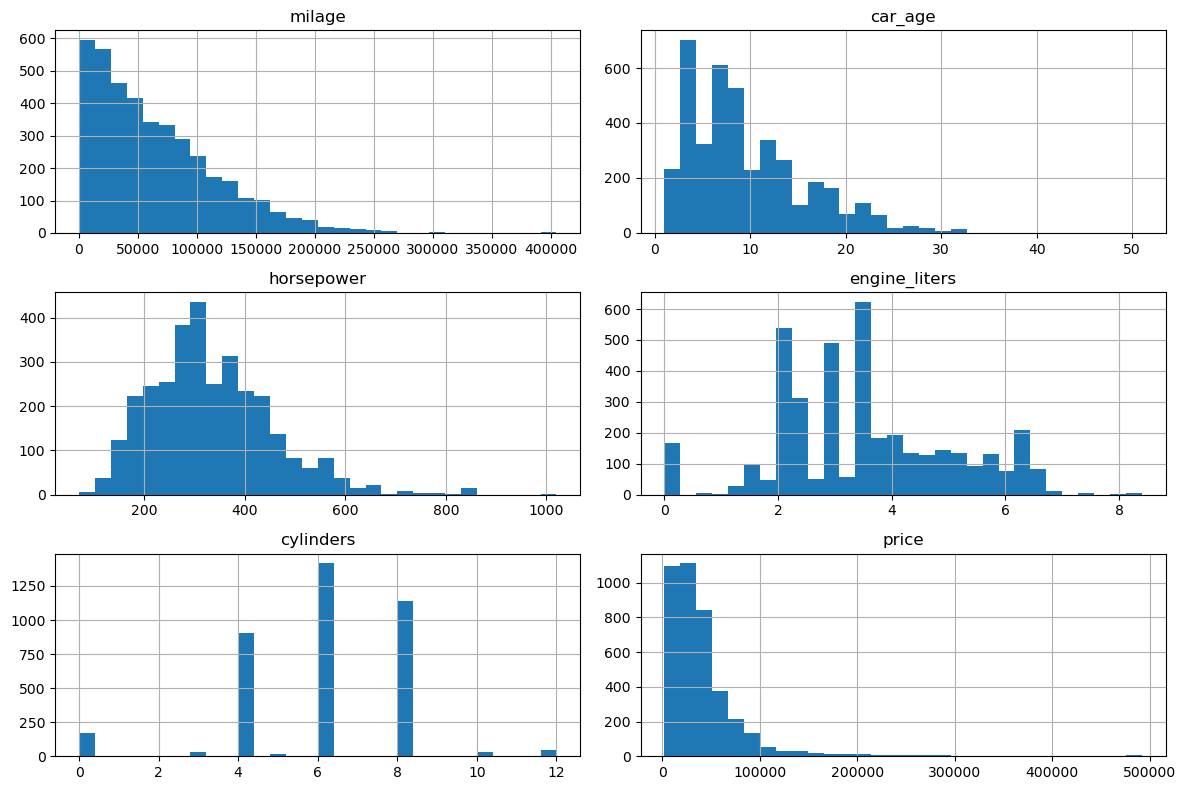

In [11]:
clean.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.savefig("figures/hist_numeric.png")
plt.show()

Milage, car_age and price are right-skewed: most cars have low mileage, are fairly new and are cheap, with a long tail of expensive cars. Horsepower is roughly bell-shaped around 300 HP and has only about 3,200 values because 20% were missing. engine_liters and cylinders take a few distinct values, and the spike at 0 is the electric cars.

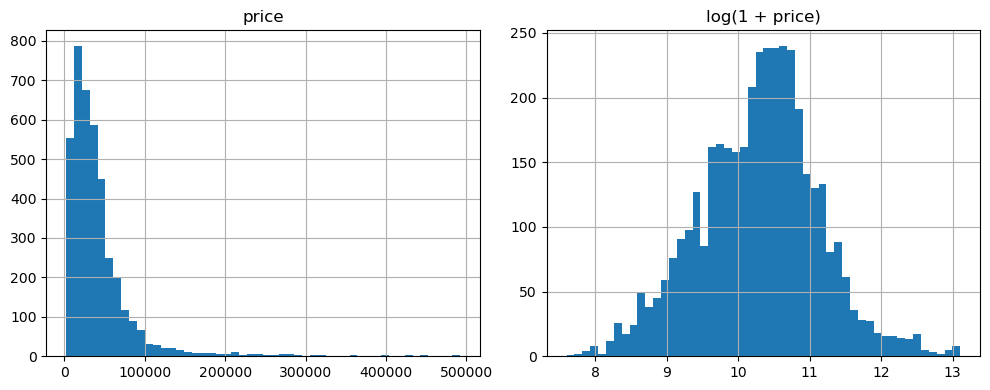

skew before: 4.358687795518588
skew after: -0.026676639906663135


In [12]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
clean["price"].hist(bins=50)
plt.title("price")

plt.subplot(1, 2, 2)
np.log1p(clean["price"]).hist(bins=50)
plt.title("log(1 + price)")

plt.tight_layout()
plt.savefig("figures/price_vs_log.png")
plt.show()

print("skew before:", clean["price"].skew())
print("skew after:", np.log1p(clean["price"]).skew())

Price skewness is 4.36 before the log transform and -0.03 after it. After log(1 + price) the distribution is close to symmetric, so the models are trained on log(1 + price) and the predictions are converted back to dollars.

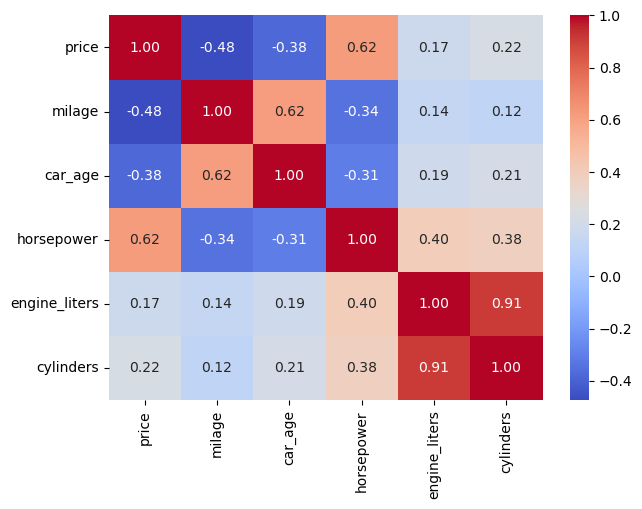

In [13]:
import seaborn as sns

corr = clean[["price", "milage", "car_age", "horsepower", "engine_liters", "cylinders"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.savefig("figures/correlation.png")
plt.show()

Horsepower has the strongest correlation with price (+0.62), followed by milage (-0.48) and car_age (-0.38). engine_liters (+0.17) and cylinders (+0.22) are weak, probably because electric cars have 0 for both but are not cheap. milage and car_age are correlated (0.62), and engine_liters and cylinders are almost the same information (0.91). Correlation only measures straight-line relationships.

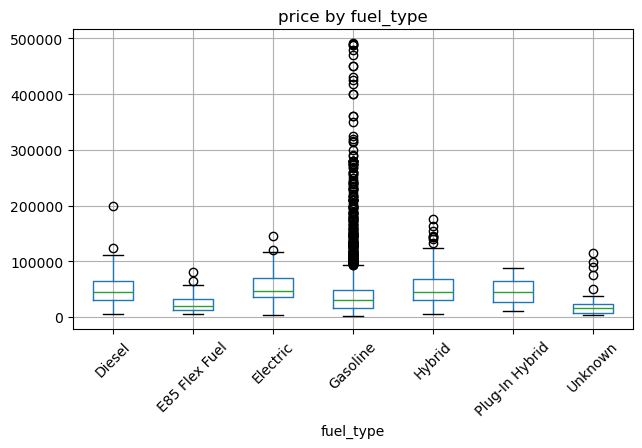

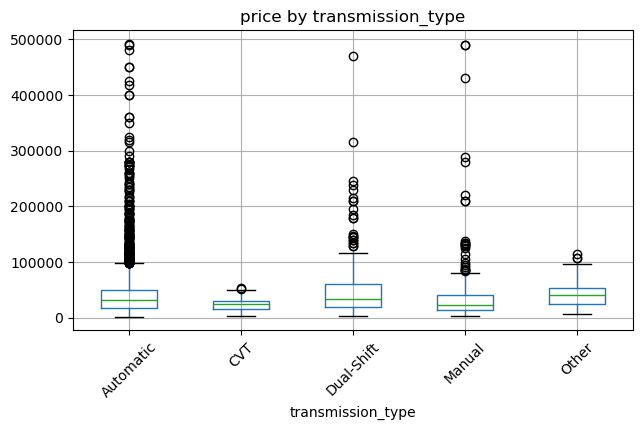

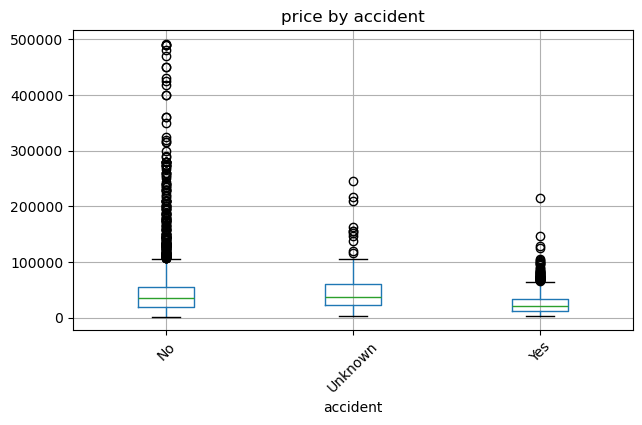

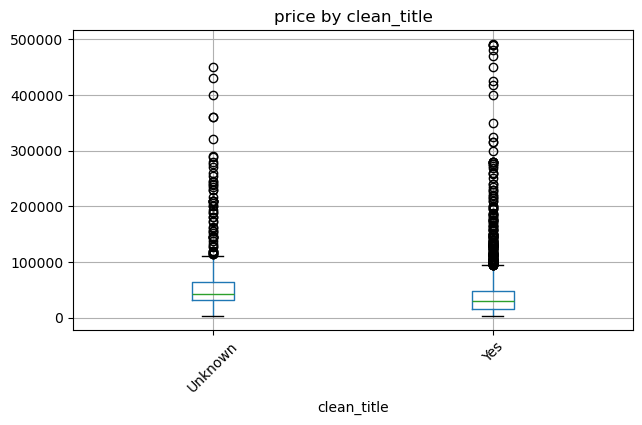

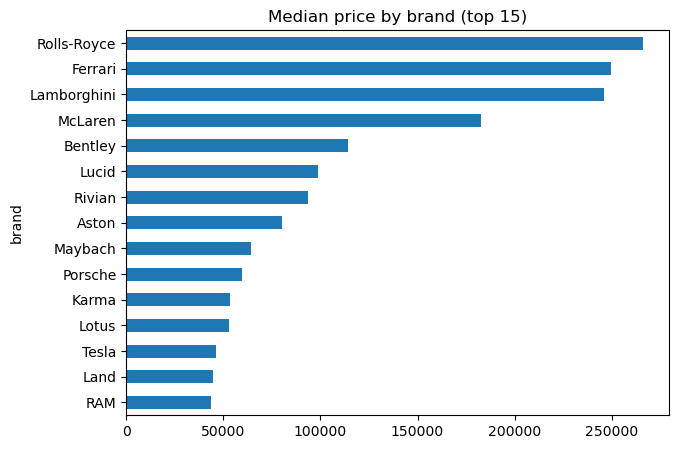

In [14]:
for col in ["fuel_type", "transmission_type", "accident", "clean_title"]:
    clean.boxplot(column="price", by=col, figsize=(7, 4))
    plt.suptitle("")
    plt.title("price by " + col)
    plt.xticks(rotation=45)
    plt.savefig("figures/box_" + col + ".png")
    plt.show()

clean.groupby("brand")["price"].median().sort_values().tail(15).plot(kind="barh", figsize=(7, 5))
plt.title("Median price by brand (top 15)")
plt.savefig("figures/brand_median_price.png")
plt.show()

Gasoline has the most outliers because almost all supercars use it. Diesel, Electric, Hybrid and Plug-In Hybrid have higher median prices (about 45k) than Gasoline (about 30k) and E85 Flex Fuel (about 25k). Cars with a reported accident are clearly cheaper (median about 22k vs about 35k). CVT is the cheapest and narrowest transmission group. Cars with a missing clean_title have a higher median price than cars marked Yes, so the missing value is kept as its own category "Unknown" instead of being treated as "No". Brand has a very large effect: the median price of Rolls-Royce, Ferrari and Lamborghini is about 245k-265k, while the 15th brand is about 43k. Medians of brands with very few cars are less reliable.

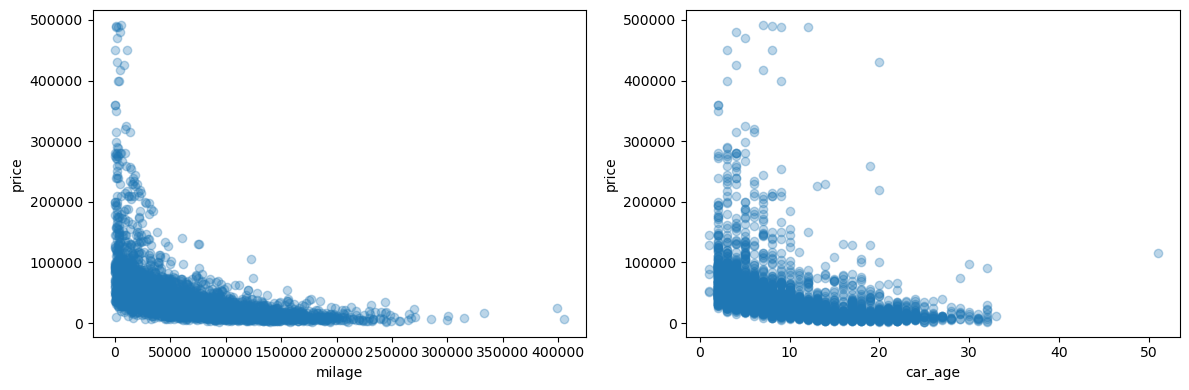

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(clean["milage"], clean["price"], alpha=0.3)
plt.xlabel("milage")
plt.ylabel("price")

plt.subplot(1, 2, 2)
plt.scatter(clean["car_age"], clean["price"], alpha=0.3)
plt.xlabel("car_age")
plt.ylabel("price")

plt.tight_layout()
plt.savefig("figures/scatter_milage_age.png")
plt.show()

Price drops quickly with milage and car_age and then flattens, so the relationship is curved, not a straight line. Young cars with low mileage have a very wide price range (brand and power matter). A plain Linear Regression on raw price will be limited by this, which is another reason to train on log(1 + price).

In [17]:
print(clean["clean_title"].value_counts())
print(clean.shape)

clean_title
Yes        3405
Unknown     596
Name: count, dtype: int64
(4001, 11)
